# DFT — quatro versões

Neste Notebook implementamos a Transformada Discreta de Fourier (DFT) e sua inversa (IDFT) de quatro formas:

1. **Sinal** — a soma da definição, amostra por amostra
2. **Base** — produto interno do sinal com cada exponencial complexa da base de Fourier
3. **Matriz** — multiplicação matriz-vetor $\mathbf{X} = \mathbf{W}\mathbf{x}$
4. **FFT** — Cooley-Tukey radix-2 com dizimação no tempo (DIT)

$$
X[k] = \sum_{n=0}^{N-1} x[n]\, e^{-j\frac{2\pi}{N}kn}
\qquad
x[n] = \frac{1}{N}\sum_{k=0}^{N-1} X[k]\, e^{+j\frac{2\pi}{N}kn}
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
import time

In [2]:
'''
Choose your Lib path
'''

try:
    from google.colab import drive

    drive.mount('/content/drive')
    # Google Colab
    LIB_PATH = '/content/drive/MyDrive/UFG/01_teaching/'

except ImportError:
    # Repositorio local: assets/lib/ fica dois niveis acima deste notebook
    LIB_PATH = os.path.abspath('../../')

sys.path.append(LIB_PATH)

In [3]:
from lib.myPlotLib import *
from lib.myAudioProcessingLib import *
from lib.mySignalProcessingLib import SIGNALgenerate

In [4]:
# Definição de diretórios
SOUND_PATH = os.path.join(LIB_PATH, 'sounds') # Pasta de arquivos de som
SOUND_FILE = 'train.wav' # Sinal de entrada

In [5]:
# Carregamos o sinal
x, fs = audioread(os.path.join(SOUND_PATH, SOUND_FILE))

In [6]:
print(x.shape, fs)

(12880,) 8192


In [7]:
play(x, fs)

In [8]:
def COMPLEXmagnitude(z, version='sqrt'):
    if version == 'sqrt':
        '''
        Legnth of z
        '''
        mag = np.sqrt(z.real**2 + z.imag**2)
    elif version == 'abs':
        '''
        |z|
        '''
        mag = np.abs(z)
        
    return mag

def COMPLEXphase(z, version='arctan2', units='rad'):
    if version == 'arctan':
        '''
        arctan
        '''
        phi = np.arctan(z.imag / z.real) # so 1o e 4o quadrantes
    elif version == 'arctan2':
        '''
        arctan2
        '''
        phi = np.arctan2(z.imag, z.real)
    else:
        '''
        angle
        '''
        phi = np.angle(z)
    
    if units == 'deg': # graus
        '''
        rad2deg
        '''
        return phi * 180 / np.pi
        
    return phi

O produto externo $\mathbf{n}\,\mathbf{n}^T$ gera todos os produtos $kn$ de uma vez — é o expoente da matriz da DFT:
$W_{kn} = e^{-j\frac{2\pi}{N}kn}$.

In [9]:
N = 5
n = np.arange(N)[:, np.newaxis] # column vector

A = n @ n.T
print(A)

[[ 0  0  0  0  0]
 [ 0  1  2  3  4]
 [ 0  2  4  6  8]
 [ 0  3  6  9 12]
 [ 0  4  8 12 16]]


In [10]:
def myDFT(x, version='fft'):
    x = np.asarray(x, dtype=complex)
    N = len(x)
    n = np.arange(N)

    if version == 'signal':
        '''
        Signal interpretation
        '''
        X = np.zeros(N, dtype=complex)
        for k in range(N):
            for m in range(N):
                X[k] += x[m] * np.exp(-2j * np.pi * k * m / N)
    
    elif version == 'basis':
        '''
        Basis expansion
        '''
        X = np.zeros(N, dtype=complex)
        for k in range(N):
            e_k  = np.exp(2j * np.pi * k * n / N) # k-esimo vetor da base
            X[k] = np.vdot(e_k, x)                # <x, e_k> = sum x[n] conj(e_k[n])
    
    elif version == 'matrix':
        '''
        Matrix-vector multiplication
        '''
        nk = n[:, np.newaxis] @ n[np.newaxis, :] # produto externo k n
        W  = np.exp(-2j * np.pi * nk / N)        # matriz da DFT
        X  = W @ x
    
    elif version == 'fft':
        '''
        Cooley-Tukey radix-2 DIT FFT
        '''
        if not np.log2(N).is_integer():
            raise ValueError('Signal length must be a power of 2')
        if N == 1:
            return x.copy()
        if N == 2:
            return np.array([x[0] + x[1], x[0] - x[1]])
        else:
            Xe = myDFT(x[0::2], version='fft') # amostras pares
            Xo = myDFT(x[1::2], version='fft') # amostras impares
            basis = np.exp(-2j * np.pi * n / N) # fatores de giro (twiddle)
            return np.append(Xe + basis[0:N//2] * Xo,
                             Xe - basis[0:N//2] * Xo)
        
    else:
        '''
        Numpy
        '''
        X = np.fft.fft(x)
    
    return X

A IDFT é a mesma operação com o sinal do expoente trocado e o fator $1/N$. Na versão FFT usamos a identidade
$\mathrm{IDFT}\{X\} = \frac{1}{N}\,\overline{\mathrm{DFT}\{\overline{X}\}}$, que reaproveita o `myDFT`.

Como os sinais deste notebook são reais, devolvemos só a parte real — a imaginária é erro de arredondamento
(da ordem de $10^{-13}$).

In [11]:
def myIDFT(X, version='ifft'):
    X = np.asarray(X, dtype=complex)
    N = len(X)
    k = np.arange(N)

    if version == 'signal':
        '''
        Signal interpretation
        '''
        x = np.zeros(N, dtype=complex)
        for m in range(N):
            for kk in range(N):
                x[m] += X[kk] * np.exp(2j * np.pi * kk * m / N)
        x /= N
    
    elif version == 'basis':
        '''
        Basis expansion
        '''
        x = np.zeros(N, dtype=complex)
        for kk in range(N):
            e_k = np.exp(2j * np.pi * kk * k / N) # k-esimo vetor da base
            x  += X[kk] * e_k                     # soma ponderada da base
        x /= N
    
    elif version == 'matrix':
        '''
        Matrix-vector multiplication
        '''
        nk = k[:, np.newaxis] @ k[np.newaxis, :]
        W  = np.exp(-2j * np.pi * nk / N)
        x  = W.conj().T @ X / N # W^-1 = W^H / N
    
    elif version == 'fft':
        '''
        Cooley-Tukey radix-2 DIT FFT
        '''
        x = np.conj(myDFT(np.conj(X), version='fft')) / N
        
    else:
        '''
        Numpy
        '''
        x = np.fft.ifft(X)
    
    return x.real

In [12]:
y = x[:1024]
play(y, fs)

In [13]:
Y1 = myDFT(y, 'signal')
# print(Y1) # DFT de y

In [14]:
print(x.dtype, Y1.dtype, len(y), len(Y1))

float64 complex128 1024 1024


In [15]:
Y2 = myDFT(y, 'basis')

In [16]:
Y3 = myDFT(y, 'matrix')

In [17]:
Y4 = myDFT(y, 'fft')

In [18]:
Y5 = myDFT(y, 'numpy')

### As quatro versões dão o mesmo resultado? E quanto custam?

As três primeiras fazem $N^2$ operações; a FFT faz $N\log_2 N$ — para $N = 1024$, cerca de 100× menos.

In [19]:
for name, Yk in [('signal', Y1), ('basis', Y2), ('matrix', Y3), ('fft', Y4)]:
    print(f"{name:>7}: igual ao numpy? {np.allclose(Yk, Y5)}  "
          f"erro max = {np.max(np.abs(Yk - Y5)):.2e}")

print()
for version in ['signal', 'basis', 'matrix', 'fft', 'numpy']:
    t0 = time.perf_counter()
    myDFT(y, version)
    print(f"{version:>7}: {1e3 * (time.perf_counter() - t0):9.2f} ms")

 signal: igual ao numpy? True  erro max = 1.19e-11
  basis: igual ao numpy? True  erro max = 1.19e-11
 matrix: igual ao numpy? True  erro max = 1.06e-11
    fft: igual ao numpy? True  erro max = 2.84e-14



 signal:    608.30 ms
  basis:     41.89 ms
 matrix:     29.13 ms
    fft:      8.40 ms
  numpy:      0.06 ms


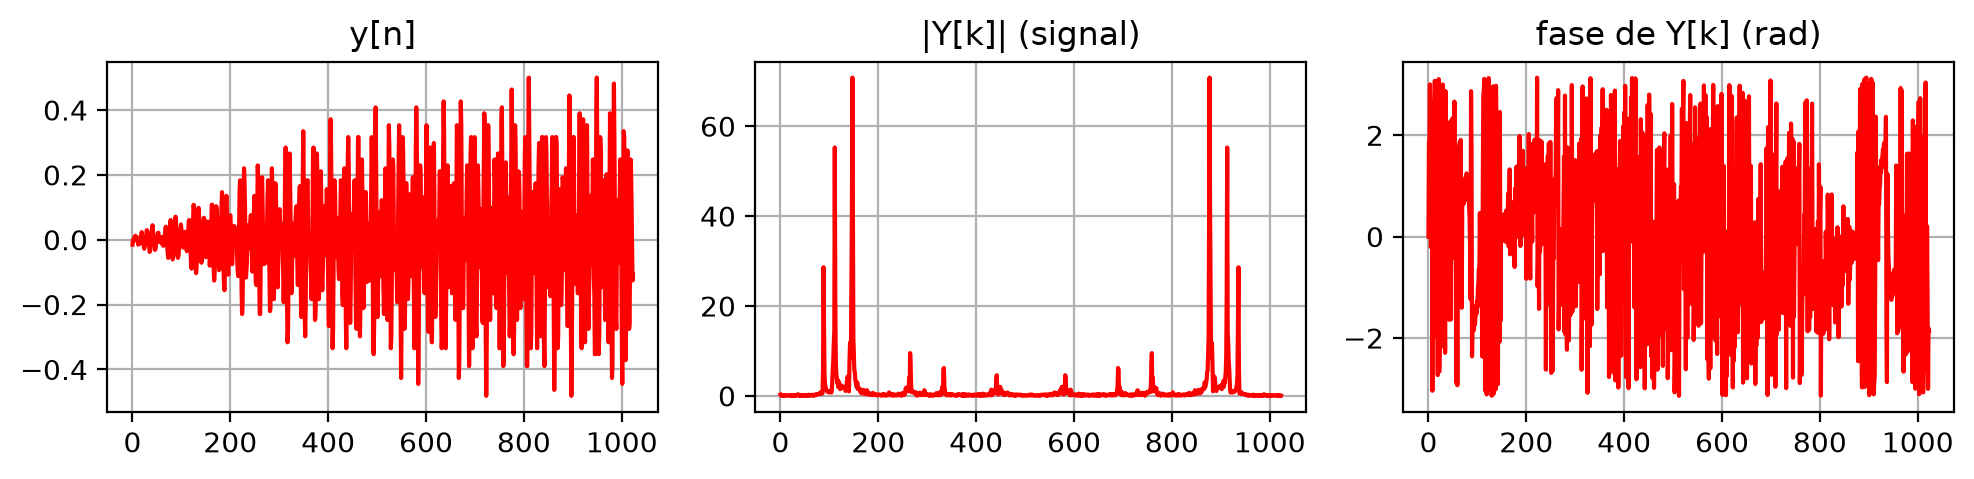

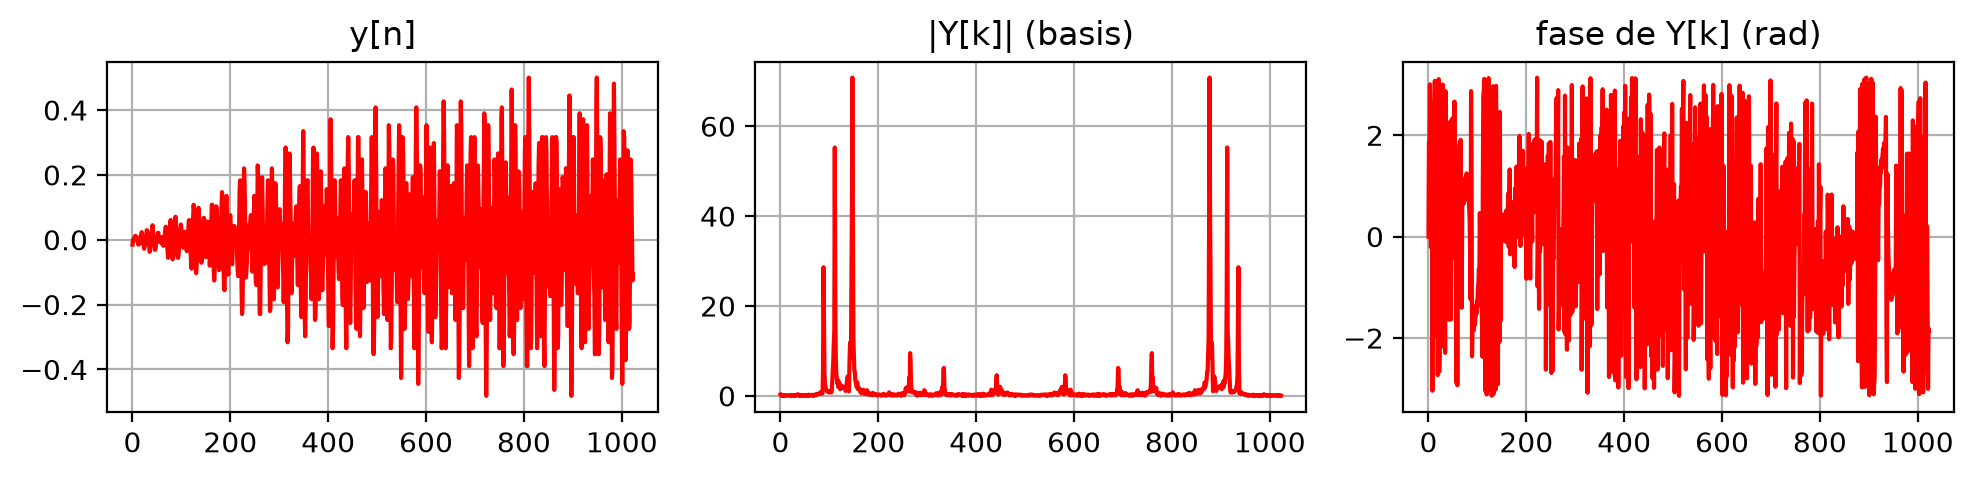

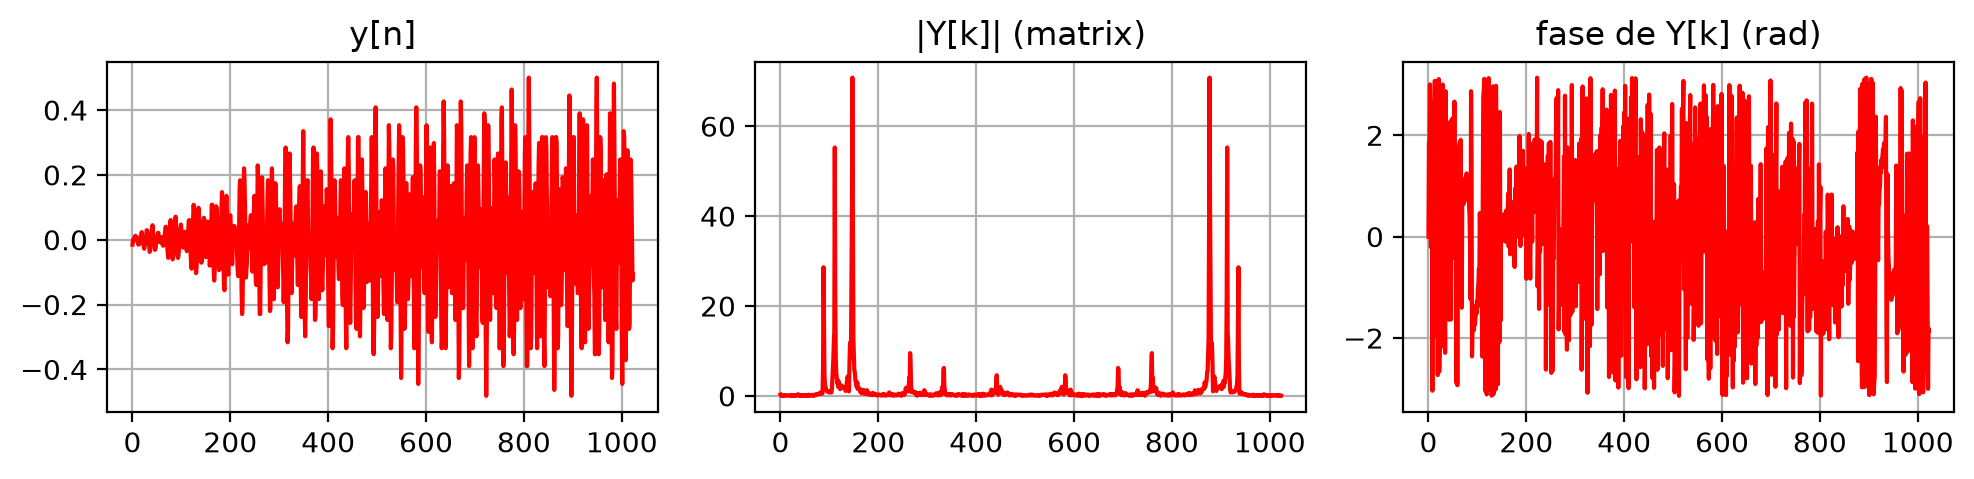

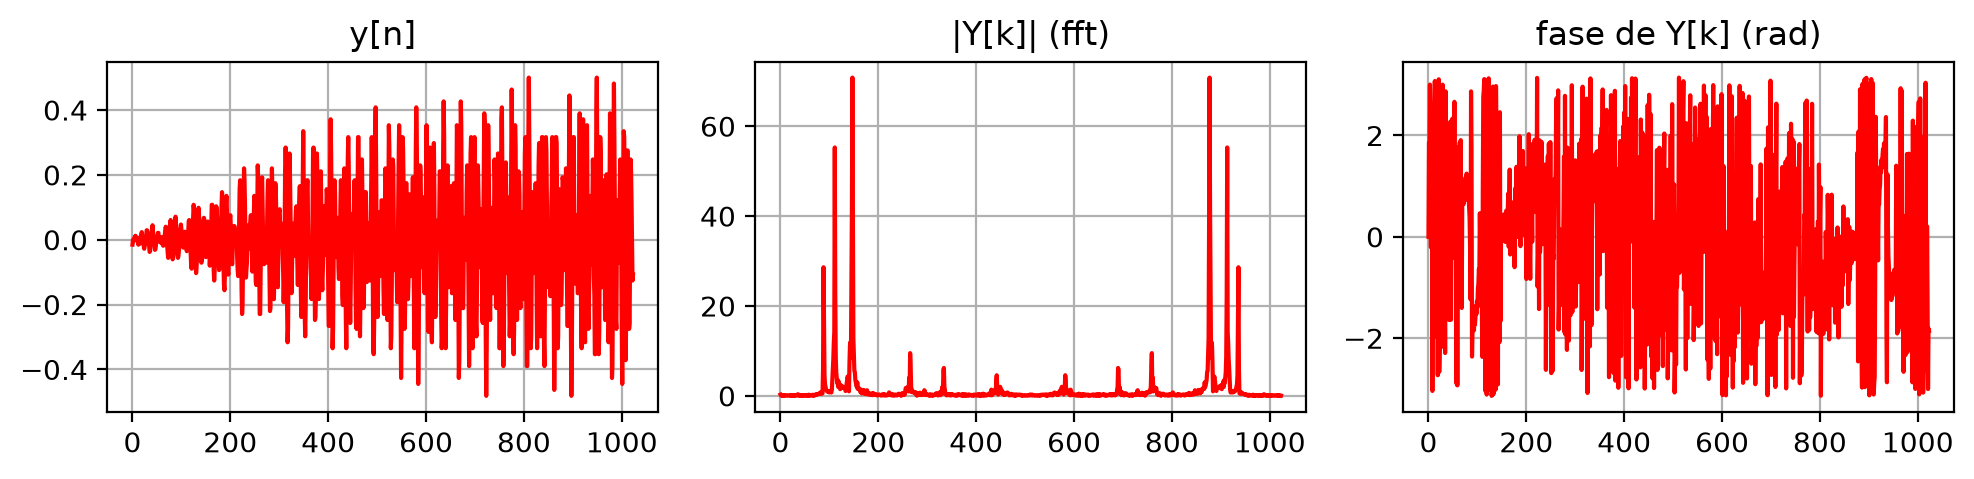

In [20]:
Y1mag = COMPLEXmagnitude(Y1) # Modulo da DFT
Y1pha = COMPLEXphase(Y1) # Fase da DFT

Y2mag = COMPLEXmagnitude(Y2) # Modulo da DFT
Y2pha = COMPLEXphase(Y2) # Fase da DFT

Y3mag = COMPLEXmagnitude(Y3) # Modulo da DFT
Y3pha = COMPLEXphase(Y3) # Fase da DFT

Y4mag = COMPLEXmagnitude(Y4) # Modulo da DFT
Y4pha = COMPLEXphase(Y4) # Fase da DFT

for title, Ymag, Ypha in [('signal', Y1mag, Y1pha), ('basis', Y2mag, Y2pha),
                          ('matrix', Y3mag, Y3pha), ('fft', Y4mag, Y4pha)]:
    fig, ax = plt.subplots(1, 3, figsize=(10, 2.5))
    ax[0].plot(y, 'r')
    ax[0].set_title('y[n]')
    ax[1].plot(Ymag, 'r')
    ax[1].set_title(f'|Y[k]| ({title})')
    ax[2].plot(Ypha, 'r')
    ax[2].set_title('fase de Y[k] (rad)')
    figureFormat(ax, fig, tight=True)
    plt.show()

## Synthesis (signal reconstruction)

float64
 signal: reconstrucao perfeita? True  erro max = 8.24e-14
  basis: reconstrucao perfeita? True  erro max = 8.23e-14
 matrix: reconstrucao perfeita? True  erro max = 9.02e-14
    fft: reconstrucao perfeita? True  erro max = 1.67e-16


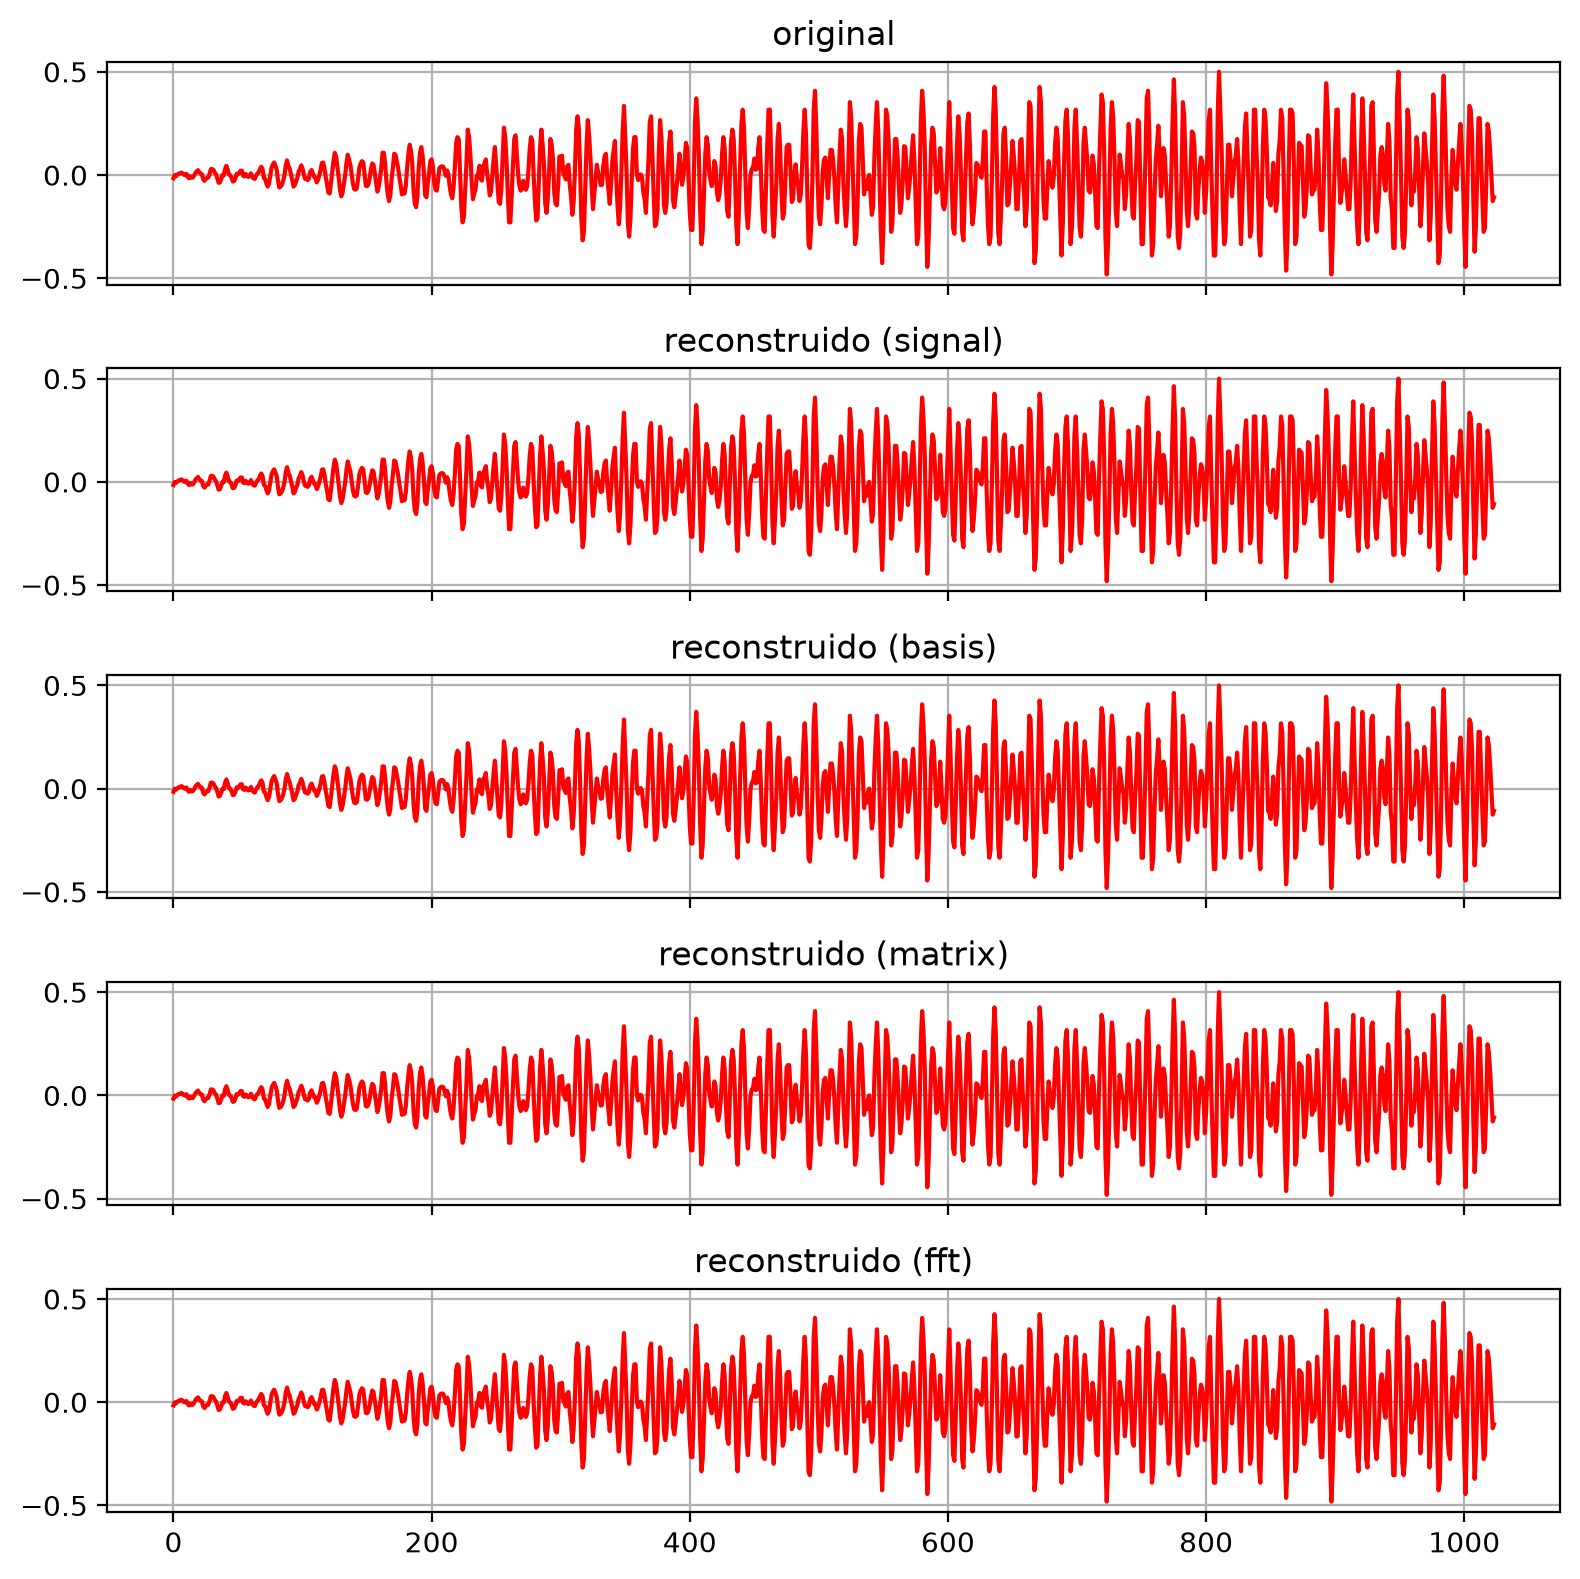

In [21]:
y1 = myIDFT(Y1, 'signal') # sinal reconstruido
y2 = myIDFT(Y2, 'basis') # sinal reconstruido
y3 = myIDFT(Y3, 'matrix') # sinal reconstruido
y4 = myIDFT(Y4, 'fft') # sinal reconstruido

print(y1.dtype)
for name, yk in [('signal', y1), ('basis', y2), ('matrix', y3), ('fft', y4)]:
    print(f"{name:>7}: reconstrucao perfeita? {np.allclose(yk, y)}  erro max = {np.max(np.abs(yk - y)):.2e}")

fig, ax = plt.subplots(5, 1, sharex=True, figsize=(8, 8))
ax[0].plot(y, 'r')
ax[0].set_title('original')
for a, yk, name in zip(ax[1:], [y1, y2, y3, y4], ['signal', 'basis', 'matrix', 'fft']):
    a.plot(yk, 'r')
    a.set_title(f'reconstruido ({name})')
figureFormat(ax, fig, tight=True)
plt.show()

Opa, precisamos apenas da metade da informacao das frequencias *DO ESPECTRO*

Plote a metade do espectro do sinal

> Para um sinal **real**, $X[N-k] = \overline{X[k]}$: o módulo é simétrico em torno de $N/2$ e a fase, antissimétrica.
> A metade $k = 0, \dots, N/2$ já contém tudo. O índice $k$ corresponde à frequência $f_k = k\,\frac{f_s}{N}$,
> e $k = N/2$ é a frequência de Nyquist $f_s/2$.

Simetria conjugada X[N-k] = conj(X[k]): True


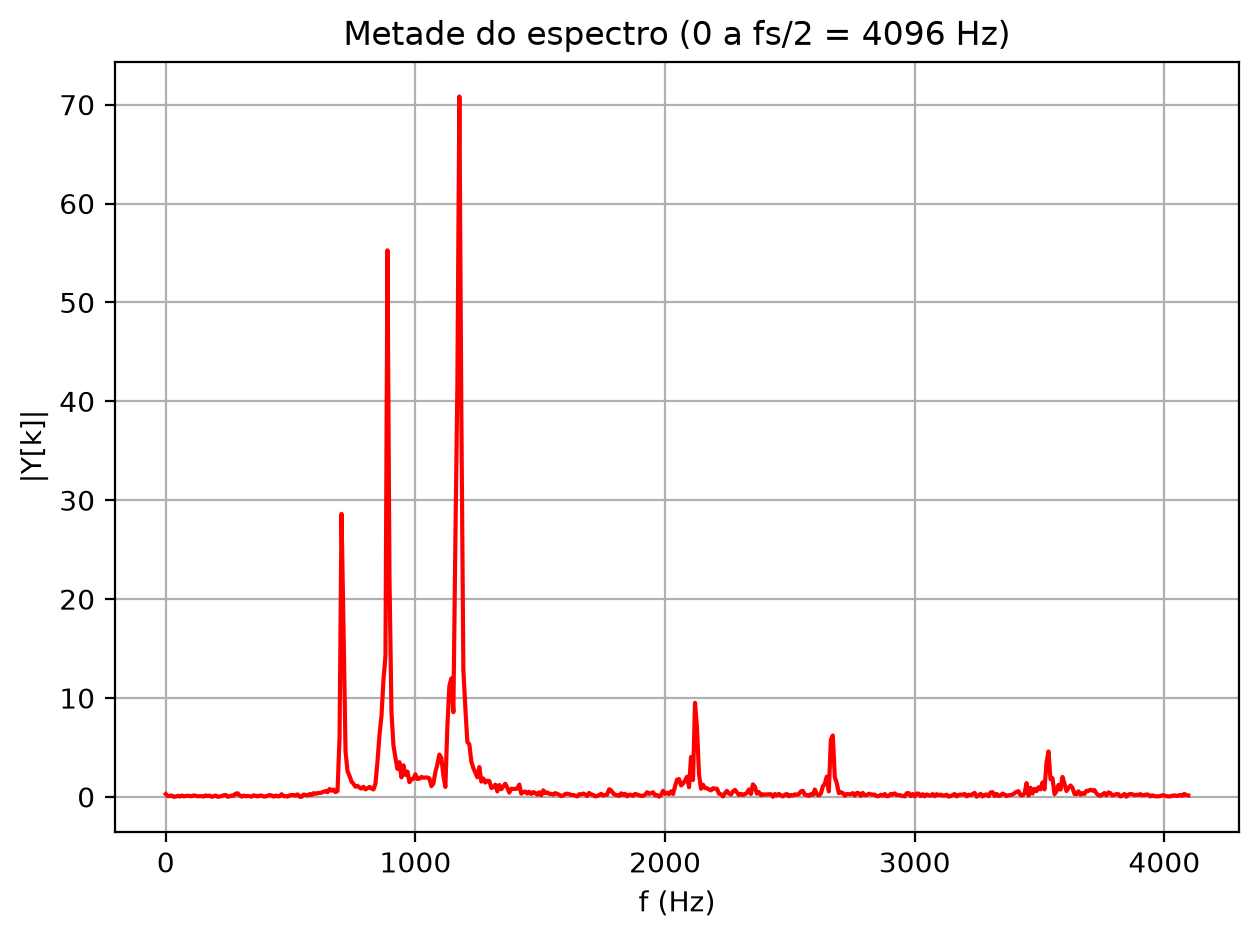

In [22]:
N = len(Y1mag)
print("Simetria conjugada X[N-k] = conj(X[k]):", np.allclose(Y1[1:], np.conj(Y1[1:][::-1])))

k = np.arange(N//2 + 1)
f = k * fs / N # Hz

fig, ax = plt.subplots()
ax.plot(f, Y1mag[:N//2 + 1], 'r')
ax.set_xlabel('f (Hz)')
ax.set_ylabel('|Y[k]|')
ax.set_title(f'Metade do espectro (0 a fs/2 = {fs/2:.0f} Hz)')
figureFormat(ax, fig, tight=True)
plt.show()

## Plots da DFT para os sinais basicos

O que esperar de cada um:

- **delta** $\delta[n]$: espectro **plano**, $|X[k]| = 1$ — o impulso contém todas as frequências por igual.
- **degrau**: concentrado em $k = 0$ (valor médio alto), decaindo com $k$.
- **exponencial** $a^n u[n]$: passa-baixas, máximo em $k = 0$.
- **oscilação** com período $P$ que divide $N$: só dois picos, em $k = N/P$ e $k = N - N/P$.
- **ruído**: espectro espalhado por todas as frequências, sem estrutura.

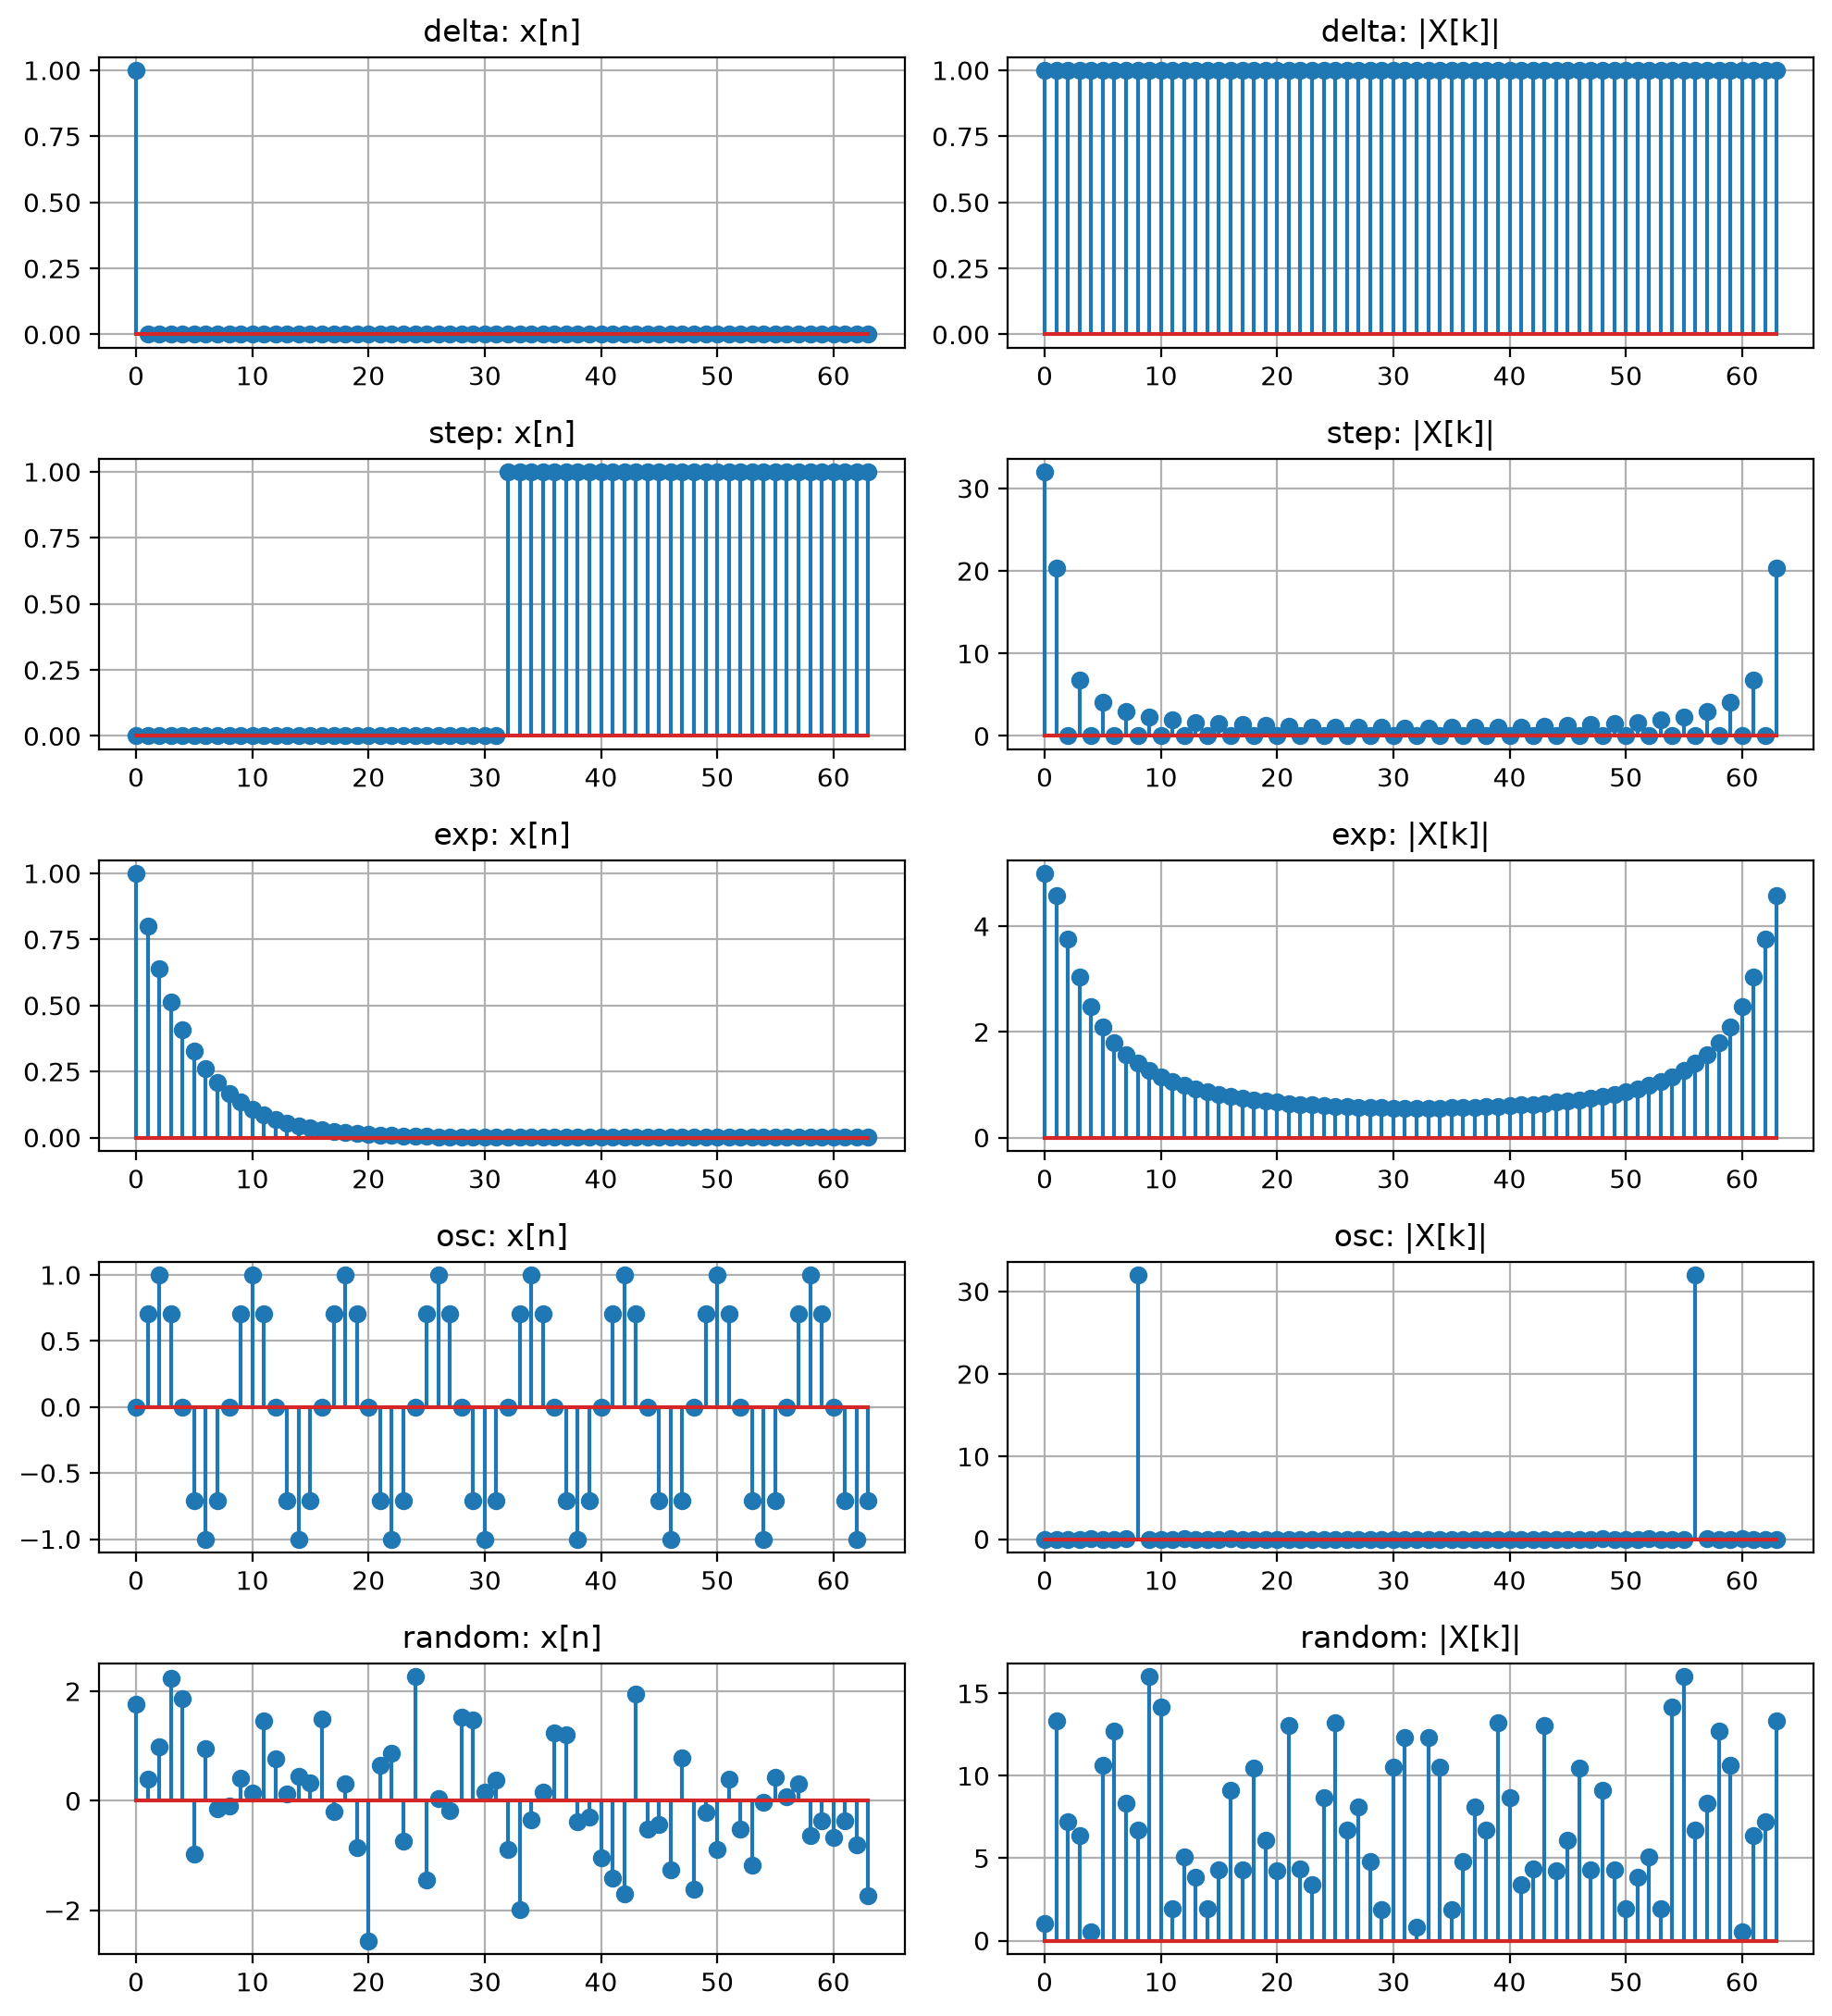

In [23]:
# Plots da DFT para os sinais basicos
N = 64
basicos = [
    ('delta', dict(signal='delta')),
    ('step',  dict(signal='step', params={'k': N//2})),
    ('exp',   dict(signal='exp', params={'a': 0.8})),
    ('osc',   dict(signal='osc', period=8)),
    ('random', dict(signal='random')),
]

np.random.seed(0)
fig, ax = plt.subplots(len(basicos), 2, figsize=(10, 11))
for i, (name, kwargs) in enumerate(basicos):
    s, n = SIGNALgenerate(N=N, **kwargs)
    S = myDFT(s.astype(float), 'fft')
    ax[i, 0].stem(n, s)
    ax[i, 0].set_title(f'{name}: x[n]')
    ax[i, 1].stem(n, COMPLEXmagnitude(S))
    ax[i, 1].set_title(f'{name}: |X[k]|')
figureFormat(ax, fig, tight=True)
plt.show()